# Language feature comparison


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## Load data and train/test split
Load both v1 and v2 datasets, restrict v1 to the same rows as v2, and apply an 80/20 train/test split.


In [2]:
path_v1 = os.path.join('..', 'data', 'cleaned_salary_data.csv')
path_v2 = os.path.join('..', 'data', 'cleaned_salary_data_v2.csv')

df_v1 = pd.read_csv(path_v1)
df_v2 = pd.read_csv(path_v2)

print(f"Loaded v1 rows: {len(df_v1)}, Loaded v2 rows: {len(df_v2)}")

base_features = [
    'Country', 'Education', 'Role', 'RemoteWork', 'OrgSize',
    'Experience_Years', 'Work_Experience_Years'
]
lang_features = [c for c in df_v2.columns if c not in base_features + ['Salary']]

# restrict v1 data to the exact rows present in v2
X_v1 = df_v2[base_features].copy()
X_v2 = df_v2[base_features + lang_features].copy()
y = df_v2['Salary'].copy()

X_v1_train, X_v1_test, y_train, y_test = train_test_split(
    X_v1, y, test_size=0.2, random_state=42
)
X_v2_train, X_v2_test, _, _ = train_test_split(
    X_v2, y, test_size=0.2, random_state=42
)

print(f"Training rows: {len(X_v1_train)}, Test rows: {len(X_v1_test)}")
print(f"v1 feature count: {X_v1_train.shape[1]}, v2 feature count: {X_v2_train.shape[1]}")


Loaded v1 rows: 16954, Loaded v2 rows: 15940
Training rows: 12752, Test rows: 3188
v1 feature count: 7, v2 feature count: 22


My observation: 


## Cross-validation comparison
Run 5-fold cross-validation on the training set only for default HistGradientBoostingRegressor on the log target, comparing v1 and v2 feature sets.


In [3]:
cat_cols = ['Country', 'Education', 'Role', 'RemoteWork', 'OrgSize']
num_cols = ['Experience_Years', 'Work_Experience_Years']

prep_v1 = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)
])

prep_v2 = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols),
    ('lang', 'passthrough', lang_features)
])

pipe_v1 = Pipeline([('prep', prep_v1), ('reg', HistGradientBoostingRegressor(random_state=42))])
pipe_v2 = Pipeline([('prep', prep_v2), ('reg', HistGradientBoostingRegressor(random_state=42))])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_maes_v1 = []
for tr_idx, val_idx in kf.split(X_v1_train, y_train):
    pipe_v1.fit(X_v1_train.iloc[tr_idx], np.log(y_train.iloc[tr_idx]))
    preds = np.exp(pipe_v1.predict(X_v1_train.iloc[val_idx]))
    cv_maes_v1.append(mean_absolute_error(y_train.iloc[val_idx], preds))

cv_maes_v2 = []
for tr_idx, val_idx in kf.split(X_v2_train, y_train):
    pipe_v2.fit(X_v2_train.iloc[tr_idx], np.log(y_train.iloc[tr_idx]))
    preds = np.exp(pipe_v2.predict(X_v2_train.iloc[val_idx]))
    cv_maes_v2.append(mean_absolute_error(y_train.iloc[val_idx], preds))

cv_summary = pd.DataFrame([
    {
        'Feature set': 'v1 (base features)',
        'CV MAE Mean ($)': np.mean(cv_maes_v1),
        'CV MAE Std ($)': np.std(cv_maes_v1)
    },
    {
        'Feature set': 'v2 (base + language features)',
        'CV MAE Mean ($)': np.mean(cv_maes_v2),
        'CV MAE Std ($)': np.std(cv_maes_v2)
    }
])
display(cv_summary)


,Feature set,CV MAE Mean ($),CV MAE Std ($)
0,v1 (base features),"27,440.2956",163.4447
1,v2 (base + language features),"26,376.1372",114.1783


My observation: 


## Test set evaluation
Fit both pipelines on the full training set and evaluate on the test set once.


In [4]:
pipe_v1.fit(X_v1_train, np.log(y_train))
pred_v1 = np.exp(pipe_v1.predict(X_v1_test))

pipe_v2.fit(X_v2_train, np.log(y_train))
pred_v2 = np.exp(pipe_v2.predict(X_v2_test))

test_summary = pd.DataFrame([
    {
        'Feature set': 'v1 (base features)',
        'MAE ($)': mean_absolute_error(y_test, pred_v1),
        'RMSE ($)': root_mean_squared_error(y_test, pred_v1),
        'R-squared': r2_score(y_test, pred_v1)
    },
    {
        'Feature set': 'v2 (base + language features)',
        'MAE ($)': mean_absolute_error(y_test, pred_v2),
        'RMSE ($)': root_mean_squared_error(y_test, pred_v2),
        'R-squared': r2_score(y_test, pred_v2)
    }
])
display(test_summary)


,Feature set,MAE ($),RMSE ($),R-squared
0,v1 (base features),"26,451.9373","38,969.7929",0.5834
1,v2 (base + language features),"25,858.0652","38,121.6257",0.6013


My observation: 


## Permutation importance
Compute test set permutation importance on the language model, grouping all language columns together as one Languages feature, and evaluating Java individually. Values are in log-salary MAE units.


,Feature,Importance Mean,Importance Std
0,Country,0.2603,0.0069
1,Work_Experience_Years,0.0693,0.0024
2,Languages,0.0218,0.0015
3,Role,0.0170,0.0016
4,OrgSize,0.0126,0.0009
5,RemoteWork,0.0120,0.0007
6,Experience_Years,0.0119,0.0008
7,Education,0.0050,0.0006
8,Java,0.0003,0.0001


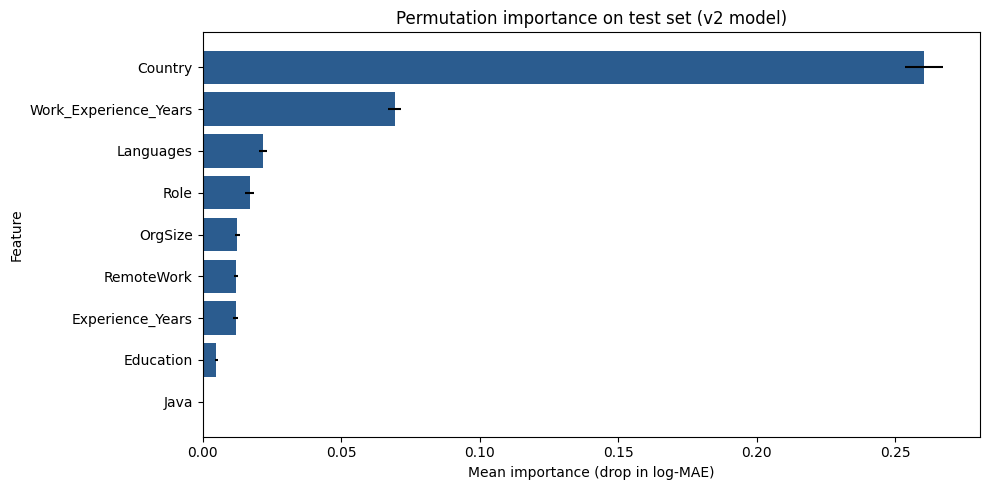

In [5]:
y_test_log = np.log(y_test)
base_preds = pipe_v2.predict(X_v2_test)
base_score = -mean_absolute_error(y_test_log, base_preds)

feature_groups = {
    'Country': ['Country'],
    'Work_Experience_Years': ['Work_Experience_Years'],
    'Role': ['Role'],
    'OrgSize': ['OrgSize'],
    'RemoteWork': ['RemoteWork'],
    'Experience_Years': ['Experience_Years'],
    'Education': ['Education'],
    'Languages': lang_features,
    'Java': ['Java']
}

rng = np.random.RandomState(42)
n_repeats = 10
perm_rows = []

for feat_name, cols in feature_groups.items():
    scores = []
    for _ in range(n_repeats):
        X_perm = X_v2_test.copy()
        perm_idx = rng.permutation(len(X_perm))
        X_perm[cols] = X_perm[cols].iloc[perm_idx].values
        perm_preds = pipe_v2.predict(X_perm)
        perm_score = -mean_absolute_error(y_test_log, perm_preds)
        scores.append(base_score - perm_score)
    perm_rows.append({
        'Feature': feat_name,
        'Importance Mean': np.mean(scores),
        'Importance Std': np.std(scores)
    })

df_perm = pd.DataFrame(perm_rows).sort_values('Importance Mean', ascending=False).reset_index(drop=True)
display(df_perm)

df_perm_plot = df_perm.sort_values('Importance Mean', ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(df_perm_plot['Feature'], df_perm_plot['Importance Mean'], xerr=df_perm_plot['Importance Std'], color='#2b5c8f')
plt.xlabel('Mean importance (drop in log-MAE)')
plt.ylabel('Feature')
plt.title('Permutation importance on test set (v2 model)')
plt.tight_layout()
plt.show()


My observation: 
